# BDD100K: YOLOv8m, Early-Exit and UEP Training

End-to-end UEPNet pipeline on BDD100K:

1. Split the official BDD100K training set once into a fixed 75% detector partition (`detector75`) and a disjoint 25% predictor partition (`predictor25`).
2. **Stage 1:** train YOLOv8m on `detector75`.
3. **Stage 2:** train the layer-6 early-exit model on `detector75`, initialised from the Stage 1 detector.
4. Generate UEP targets (the early exit's per-image F1-score) on `predictor25` and on the validation set.
5. Train the UEP regressors on all of `predictor25` and evaluate the routed system.

The official BDD100K validation set is never part of either partition and is used to validate every stage. Every stage saves resumable checkpoints.

In [1]:
import os
import shutil
import glob

EXP_DIR = "/kaggle/working/bdd100k_75_25_experiment"

# Restore a previous run of this experiment (split, checkpoints, models) from /kaggle/input/, if attached
matches = glob.glob("/kaggle/input/**/bdd100k_75_25_experiment", recursive=True)

if not matches:
    # Also check if the contents were mounted directly under the dataset folder
    matches = [
        p for p in glob.glob("/kaggle/input/**/checkpoints", recursive=True)
        if "bdd100k" in p
    ]
    if matches:
        matches = [os.path.dirname(matches[0])]

if matches:
    restore_src = matches[0]
    print(f"Found checkpoint source at: {restore_src}")
    
    if os.path.exists(EXP_DIR):
        print(f"{EXP_DIR} already exists. Removing existing directory to restore clean checkpoint...")
        shutil.rmtree(EXP_DIR)
        
    print(f"Copying from {restore_src} to {EXP_DIR}...")
    shutil.copytree(restore_src, EXP_DIR)
    print("Restoration complete! Files ready:")
    for root, dirs, files in os.walk(EXP_DIR):
        depth = root.replace(EXP_DIR, "").count(os.sep)
        if depth <= 2:
            print(f"{'  ' * depth} - {os.path.basename(root)}/ ({len(files)} files)")
else:
    print("Could not find bdd100k_75_25_experiment in /kaggle/input/.")
    print("Available folders in /kaggle/input/:")
    for item in os.listdir("/kaggle/input"):
        print(f"  - /kaggle/input/{item}")

Found checkpoint source at: /kaggle/input/datasets/ank1tha/bdd100k-experiment-checkpoint/bdd100k_75_25_experiment
Copying from /kaggle/input/datasets/ank1tha/bdd100k-experiment-checkpoint/bdd100k_75_25_experiment to /kaggle/working/bdd100k_75_25_experiment...
Restoration complete! Files ready:
 - bdd100k_75_25_experiment/ (0 files)
   - splits/ (5 files)
   - configs/ (3 files)
   - checkpoints/ (0 files)
     - yolov8m_early_exit/ (6 files)
     - yolov8m_detector/ (20 files)


In [2]:
# Kaggle already supplies NumPy, OpenCV, PyTorch, and torchvision. Do not reinstall them:
# replacing NumPy in a live kernel can break the preinstalled cv2 binary and requires a restart.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('ultralytics') is None:
    # --no-deps deliberately preserves Kaggle's compatible NumPy/OpenCV stack.
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'ultralytics'])
else:
    print('Using the Ultralytics version already provided by Kaggle.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.6 MB/s eta 0:00:00


In [3]:
import copy
import csv
import json
import os
import random
from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import yaml
from PIL import Image
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.models import EfficientNet_B0_Weights, MobileNet_V3_Small_Weights, ResNet18_Weights
from tqdm.auto import tqdm
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

# BDD100K / YOLO configuration
SEED = 42
DETECTOR_EPOCHS = 300
DETECTOR_PATIENCE = 30
IMAGE_SIZE = 640
DETECTOR_BATCH = 64
YOLO_DEVICE = [0, 1]

# UEP regression configuration
UEP_EPOCHS = 50
UEP_PATIENCE = 5
UEP_BATCH = 64

# `last.pt` is saved every epoch by Ultralytics and is sufficient for native resume.
# Do not retain a complete epochNN.pt archive after every epoch on Kaggle storage.
YOLO_SAVE_PERIOD = -1

EXPERIMENT_DIR = Path('/kaggle/working/bdd100k_75_25_experiment')
SPLITS_DIR = EXPERIMENT_DIR / 'splits'
CHECKPOINTS_DIR = EXPERIMENT_DIR / 'checkpoints'
MODELS_DIR = EXPERIMENT_DIR / 'models'
RESULTS_DIR = EXPERIMENT_DIR / 'results'
LOGS_DIR = EXPERIMENT_DIR / 'logs'
CONFIGS_DIR = EXPERIMENT_DIR / 'configs'
for directory in (SPLITS_DIR, CHECKPOINTS_DIR, MODELS_DIR, RESULTS_DIR, LOGS_DIR, CONFIGS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DETECTOR_RUN_DIR = CHECKPOINTS_DIR / 'yolov8m_detector'
EARLY_EXIT_RUN_DIR = CHECKPOINTS_DIR / 'yolov8m_early_exit'
UEP_RUN_DIR = CHECKPOINTS_DIR / 'uep'
for directory in (DETECTOR_RUN_DIR, EARLY_EXIT_RUN_DIR, UEP_RUN_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DETECTOR_LAST = DETECTOR_RUN_DIR / 'weights' / 'last.pt'
DETECTOR_BEST = DETECTOR_RUN_DIR / 'weights' / 'best.pt'
EARLY_EXIT_LAST = EARLY_EXIT_RUN_DIR / 'weights' / 'last.pt'
EARLY_EXIT_BEST = EARLY_EXIT_RUN_DIR / 'weights' / 'best.pt'

DETECTOR_DONE = DETECTOR_RUN_DIR / 'stage_completed.json'
EARLY_EXIT_DONE = EARLY_EXIT_RUN_DIR / 'stage_completed.json'

print(f'Experiment directory: {EXPERIMENT_DIR}')
print('Existing artifacts will be reused. To resume in a new Kaggle session, save this directory as notebook output or a Kaggle Dataset and attach/copy it back before running.')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Experiment directory: /kaggle/working/bdd100k_75_25_experiment
Existing artifacts will be reused. To resume in a new Kaggle session, save this directory as notebook output or a Kaggle Dataset and attach/copy it back before running.


## Locate the BDD100K dataset

The YOLO-format BDD100K dataset is expected as a Kaggle input. Its root is found with `kagglehub`, falling back to the standard Kaggle input paths.

In [4]:
# Discover BDD100K dataset root. Try kagglehub first, then fall back to the known Kaggle input path.
BDD100K_ROOT = None

# Attempt 1: kagglehub
try:
    import kagglehub
    _kagglehub_path = kagglehub.dataset_download('saathvik16/bdd100k-object-dection-with-yolo-format-labels')
    _candidate = Path(_kagglehub_path)
    # kagglehub may return the versioned root; the actual dataset content is under 100k-dataset/.
    if (_candidate / '100k-dataset').is_dir():
        BDD100K_ROOT = (_candidate / '100k-dataset').resolve()
    elif (_candidate / 'train' / 'images').is_dir():
        BDD100K_ROOT = _candidate.resolve()
    print(f'kagglehub resolved BDD100K to: {BDD100K_ROOT}')
except Exception as kh_err:
    print(f'kagglehub not available or download failed: {kh_err}')

# Attempt 2: standard Kaggle input mount
if BDD100K_ROOT is None or not BDD100K_ROOT.is_dir():
    _fallback = Path('/kaggle/input/bdd100k-object-dection-with-yolo-format-labels/100k-dataset')
    if _fallback.is_dir():
        BDD100K_ROOT = _fallback.resolve()
        print(f'Using Kaggle input mount: {BDD100K_ROOT}')

# Attempt 3: datasets variant path (some Kaggle environments use /kaggle/input/datasets/...).
if BDD100K_ROOT is None or not BDD100K_ROOT.is_dir():
    _fallback2 = Path('/kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset')
    if _fallback2.is_dir():
        BDD100K_ROOT = _fallback2.resolve()
        print(f'Using Kaggle datasets mount: {BDD100K_ROOT}')

if BDD100K_ROOT is None or not BDD100K_ROOT.is_dir():
    raise FileNotFoundError(
        'Could not locate the BDD100K dataset. Attach the Kaggle dataset '
        '"saathvik16/bdd100k-object-dection-with-yolo-format-labels" to this notebook.'
    )

print(f'BDD100K dataset root: {BDD100K_ROOT}')

kagglehub resolved BDD100K to: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset
BDD100K dataset root: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset


In [5]:
TRAIN_IMAGES_DIR = (BDD100K_ROOT / 'train' / 'images').resolve()
VAL_IMAGES_DIR = (BDD100K_ROOT / 'val' / 'images').resolve()
TRAIN_LABELS_DIR = (BDD100K_ROOT / 'train' / 'labels').resolve()
VAL_LABELS_DIR = (BDD100K_ROOT / 'val' / 'labels').resolve()

required_paths = {
    'train/images': TRAIN_IMAGES_DIR,
    'train/labels': TRAIN_LABELS_DIR,
    'val/images': VAL_IMAGES_DIR,
    'val/labels': VAL_LABELS_DIR,
}
for name, path in required_paths.items():
    if not path.is_dir():
        raise FileNotFoundError(f'BDD100K dataset does not contain expected directory {name}: {path}')

IMAGE_SUFFIXES = {'.bmp', '.dng', '.jpeg', '.jpg', '.mpo', '.png', '.tif', '.tiff', '.webp', '.pfm'}
train_images = sorted(path for path in TRAIN_IMAGES_DIR.iterdir() if path.suffix.lower() in IMAGE_SUFFIXES)
val_images = sorted(path for path in VAL_IMAGES_DIR.iterdir() if path.suffix.lower() in IMAGE_SUFFIXES)

print('Discovered BDD100K paths and counts:')
for name, path in required_paths.items():
    count = len([p for p in path.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES]) if 'images' in name else len(list(path.glob('*.txt')))
    print(f'  {name}: {path} ({count} files)')
print(f'  official BDD100K train images: {len(train_images)}')
print(f'  official BDD100K val images:   {len(val_images)}')

# BDD100K class definitions (10 classes, from the dataset's data.yaml).
original_names = {
    0: 'bike',
    1: 'bus',
    2: 'car',
    3: 'motor',
    4: 'person',
    5: 'rider',
    6: 'traffic light',
    7: 'traffic sign',
    8: 'train',
    9: 'truck',
}
print(f'BDD100K class names: {original_names}')

Discovered BDD100K paths and counts:
  train/images: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/train/images (70000 files)
  train/labels: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/train/labels (70000 files)
  val/images: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val/images (10000 files)
  val/labels: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val/labels (10000 files)
  official BDD100K train images: 70000
  official BDD100K val images:   10000
BDD100K class names: {0: 'bike', 1: 'bus', 2: 'car', 3: 'motor', 4: 'person', 5: 'rider', 6: 'traffic light', 7: 'traffic sign', 8: 'train', 9: 'truck'}


## Fixed 75/25 split

`detector75.txt` and `predictor25.txt` record the split, one `BDD100K_ROOT`-relative image path per line (for example `train/images/b1c9c847-3bda4659.jpg`). Absolute-path manifests for Ultralytics are generated from them at runtime, so the split stays portable. An existing split is reused as-is and never regenerated.

In [6]:
DETECTOR_SPLIT = SPLITS_DIR / 'detector75.txt'
PREDICTOR_SPLIT = SPLITS_DIR / 'predictor25.txt'
SPLIT_METADATA = SPLITS_DIR / 'split_metadata.json'


def read_nonempty_lines(path):
    return [line.strip() for line in Path(path).read_text().splitlines() if line.strip()]


def relative_image_path(path):
    return path.resolve().relative_to(BDD100K_ROOT).as_posix()


all_train_relative = [relative_image_path(path) for path in train_images]
expected_detector_count = int(len(all_train_relative) * 0.75)
expected_predictor_count = len(all_train_relative) - expected_detector_count

if DETECTOR_SPLIT.exists() or PREDICTOR_SPLIT.exists() or SPLIT_METADATA.exists():
    # Never repair/regenerate an existing split: fail loudly if it is incomplete or corrupt.
    if not (DETECTOR_SPLIT.is_file() and PREDICTOR_SPLIT.is_file() and SPLIT_METADATA.is_file()):
        raise RuntimeError('Found partial persisted split artifacts. Restore the complete split directory; refusing to regenerate a different split.')
    detector_relative = read_nonempty_lines(DETECTOR_SPLIT)
    predictor_relative = read_nonempty_lines(PREDICTOR_SPLIT)
    split_metadata = json.loads(SPLIT_METADATA.read_text())
    print(f'Reusing persisted split created at: {split_metadata.get("created_at", "unknown")}')
else:
    shuffled_relative = all_train_relative.copy()
    random.Random(SEED).shuffle(shuffled_relative)
    detector_relative = shuffled_relative[:expected_detector_count]
    predictor_relative = shuffled_relative[expected_detector_count:]
    DETECTOR_SPLIT.write_text('\n'.join(detector_relative) + '\n')
    PREDICTOR_SPLIT.write_text('\n'.join(predictor_relative) + '\n')
    split_metadata = {
        'dataset_name': 'BDD100K official training set',
        'dataset_root_relative_format': 'one POSIX path relative to BDD100K_ROOT per line',
        'detector_split_file': DETECTOR_SPLIT.name,
        'predictor_split_file': PREDICTOR_SPLIT.name,
        'total_train_images': len(all_train_relative),
        'detector_fraction': 0.75,
        'predictor_fraction': 0.25,
        'detector_image_count': len(detector_relative),
        'predictor_image_count': len(predictor_relative),
        'random_seed': SEED,
        'created_at': datetime.now(timezone.utc).isoformat(),
    }
    SPLIT_METADATA.write_text(json.dumps(split_metadata, indent=2) + '\n')
    print('Created and persisted a new fixed 75/25 split.')

detector_set = set(detector_relative)
predictor_set = set(predictor_relative)
all_train_set = set(all_train_relative)
if len(detector_relative) != expected_detector_count or len(predictor_relative) != expected_predictor_count:
    raise RuntimeError(f'Persisted split counts are invalid: detector={len(detector_relative)}, predictor={len(predictor_relative)}')
if detector_set & predictor_set:
    raise RuntimeError('Persisted split overlaps; refusing to continue.')
if detector_set | predictor_set != all_train_set:
    raise RuntimeError('Persisted split does not exactly cover the current official BDD100K train set.')

print('Split summary:')
print(f'  Detector/backbone/early-exit train: {len(detector_relative)} images (75%)')
print(f'  UEP-only predictor subset:           {len(predictor_relative)} images (25%)')
print(f'  Overlap: {len(detector_set & predictor_set)}')
print(f'  Coverage: {len(detector_set) + len(predictor_set)} / {len(all_train_set)}')


print(f'  UEP training set: entire predictor25 subset ({len(predictor_relative)} images)')
print(f'  UEP validation set: official BDD100K val ({len(val_images)} images, untouched)')

Reusing persisted split created at: 2026-09-27T01:59:39.321154+00:00
Split summary:
  Detector/backbone/early-exit train: 52500 images (75%)
  UEP-only predictor subset:           17500 images (25%)
  Overlap: 0
  Coverage: 70000 / 70000
  UEP training set: entire predictor25 subset (17500 images)
  UEP validation set: official BDD100K val (10000 images, untouched)


## Runtime manifests and data YAMLs

Resolves the split files to absolute-path manifests and writes the data YAMLs. Training uses `detector75`; validation uses the official BDD100K validation images.

In [7]:
DETECTOR_RUNTIME_MANIFEST = SPLITS_DIR / 'detector75_ultralytics_runtime.txt'
PREDICTOR_RUNTIME_MANIFEST = SPLITS_DIR / 'predictor25_ultralytics_runtime.txt'
DETECTOR_YAML = CONFIGS_DIR / 'bdd100k_detector75.yaml'
UEP_EVAL_YAML = CONFIGS_DIR / 'bdd100k_uep_eval.yaml'
EARLY_MODEL_YAML = CONFIGS_DIR / 'yolov8m_early.yaml'


def write_runtime_manifest(relative_paths, destination):
    absolute_paths = []
    for relative_path in relative_paths:
        image_path = (BDD100K_ROOT / relative_path).resolve()
        if not image_path.is_file():
            raise FileNotFoundError(f'Split image is unavailable in BDD100K dataset: {image_path}')
        absolute_paths.append(str(image_path))
    destination.write_text('\n'.join(absolute_paths) + '\n')
    return absolute_paths


detector_runtime_paths = write_runtime_manifest(detector_relative, DETECTOR_RUNTIME_MANIFEST)
predictor_runtime_paths = write_runtime_manifest(predictor_relative, PREDICTOR_RUNTIME_MANIFEST)

detector_yaml = {
    'path': str(BDD100K_ROOT),
    'train': str(DETECTOR_RUNTIME_MANIFEST),
    'val': str(VAL_IMAGES_DIR),  # Official BDD100K validation set; never partitioned.
    'names': original_names,
}
uep_eval_yaml = {
    'path': str(BDD100K_ROOT),
    'train': str(PREDICTOR_RUNTIME_MANIFEST),
    'val': str(VAL_IMAGES_DIR),  # Same untouched official BDD100K validation set used by all stages.
    'names': original_names,
}
DETECTOR_YAML.write_text(yaml.safe_dump(detector_yaml, sort_keys=False))
UEP_EVAL_YAML.write_text(yaml.safe_dump(uep_eval_yaml, sort_keys=False))

# Early-exit model architecture
EARLY_MODEL_YAML.write_text("""nc: 10
scales:
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]
  m: [0.67, 0.75, 768]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.25, 512]

# Backbone up to layer 6
backbone:
  - [-1, 1, Conv, [64, 3, 2]]      # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]     # 1-P2/4
  - [-1, 3, C2f, [128, True]]      # 2
  - [-1, 1, Conv, [256, 3, 2]]     # 3-P3/8
  - [-1, 6, C2f, [256, True]]      # 4 <- P3 features
  - [-1, 1, Conv, [512, 3, 2]]     # 5-P4/16
  - [-1, 6, C2f, [512, True]]      # 6 <- EXIT POINT

# Dual-scale detection head (P3 and P4)
head:
  # P4 branch (from layer 6)
  - [-1, 1, Conv, [384, 3, 1]]     # 7 - reduce channels
  - [-1, 1, Conv, [384, 3, 1]]     # 8 - refine features
  
  # P3 branch (upsample and concat with layer 4)
  - [-1, 1, nn.Upsample, [None, 2, \"nearest\"]]  # 9
  - [[-1, 4], 1, Concat, [1]]                   # 10 - cat P3 from layer 4
  - [-1, 2, C2f, [256]]                         # 11 - process P3
  
  # P4 processing (from upsampled features)
  - [8, 1, Conv, [512, 3, 1]]                   # 12 - final P4 refinement
  
  # Dual-scale detection
  - [[11, 12], 1, Detect, [nc]]                 # 13 - Detect(P3, P4)
""")

print(f'Created detector YAML: {DETECTOR_YAML}')
print(f'Created UEP evaluation YAML: {UEP_EVAL_YAML}')
print(f'Created unchanged early-exit model YAML: {EARLY_MODEL_YAML}')
print(DETECTOR_YAML.read_text())

Created detector YAML: /kaggle/working/bdd100k_75_25_experiment/configs/bdd100k_detector75.yaml
Created UEP evaluation YAML: /kaggle/working/bdd100k_75_25_experiment/configs/bdd100k_uep_eval.yaml
Created unchanged early-exit model YAML: /kaggle/working/bdd100k_75_25_experiment/configs/yolov8m_early.yaml
path: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset
train: /kaggle/working/bdd100k_75_25_experiment/splits/detector75_ultralytics_runtime.txt
val: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val/images
names:
  0: bike
  1: bus
  2: car
  3: motor
  4: person
  5: rider
  6: traffic light
  7: traffic sign
  8: train
  9: truck



In [8]:
# Ultralytics parses this generated YAML before any expensive training begins.
validated_detector_data = check_det_dataset(str(DETECTOR_YAML), autodownload=False)
validated_train_manifest = Path(validated_detector_data['train'])
if validated_train_manifest.resolve() != DETECTOR_RUNTIME_MANIFEST.resolve():
    raise RuntimeError(f'Ultralytics did not retain the detector manifest: {validated_train_manifest}')
validated_lines = read_nonempty_lines(validated_train_manifest)
if len(validated_lines) != len(detector_relative):
    raise RuntimeError(f'Ultralytics detector manifest count is {len(validated_lines)}, expected {len(detector_relative)}')
if set(validated_lines) & set(predictor_runtime_paths):
    raise RuntimeError('Detector manifest contains an image from predictor25.')
print(f'Ultralytics accepted {DETECTOR_YAML} with {len(validated_lines)} detector images.')
print(f'Official validation remains: {validated_detector_data["val"]}')

Ultralytics accepted /kaggle/working/bdd100k_75_25_experiment/configs/bdd100k_detector75.yaml with 52500 detector images.
Official validation remains: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val/images


## Stage 1: YOLOv8m detector on detector75

`last.pt` is saved every epoch with the optimizer and scheduler state needed for `resume=True`; per-epoch archives are disabled to save Kaggle storage.

A completion marker stops a finished stage from being resumed or rerun. Without it, an existing `last.pt` is resumed.

In [9]:
def write_stage_complete(path, **details):
    payload = {'completed_at': datetime.now(timezone.utc).isoformat(), **details}
    Path(path).write_text(json.dumps(payload, indent=2) + '\n')


def reclaim_yolo_checkpoint_space(last_checkpoint):
    """Keep native-resume `last.pt` and `best.pt`; remove only redundant epochNN.pt archives."""
    weights_dir = Path(last_checkpoint).parent
    archived_checkpoints = sorted(weights_dir.glob('epoch*.pt'))
    if archived_checkpoints:
        reclaimed_bytes = sum(checkpoint.stat().st_size for checkpoint in archived_checkpoints if checkpoint.exists())
        for checkpoint in archived_checkpoints:
            checkpoint.unlink()
        print(f'Removed {len(archived_checkpoints)} redundant epoch archives ({reclaimed_bytes / 2**30:.2f} GiB). Kept last.pt and best.pt.')

    # Native resume restores saved train_args. Update that state so it does not recreate epochNN.pt archives.
    if Path(last_checkpoint).is_file():
        try:
            checkpoint = torch.load(last_checkpoint, map_location='cpu', weights_only=False)
        except TypeError:
            checkpoint = torch.load(last_checkpoint, map_location='cpu')
        train_args = checkpoint.get('train_args')
        if isinstance(train_args, dict) and train_args.get('save_period') != YOLO_SAVE_PERIOD:
            train_args['save_period'] = YOLO_SAVE_PERIOD
            torch.save(checkpoint, last_checkpoint)
            print(f'Updated native resume settings in {last_checkpoint}: save_period={YOLO_SAVE_PERIOD}.')


if DETECTOR_DONE.is_file() and DETECTOR_LAST.is_file():
    print(f'Detector stage already complete. Reusing: {DETECTOR_LAST}')
elif DETECTOR_LAST.is_file():
    print(f'Found existing checkpoint:\n{DETECTOR_LAST}\n\nReclaiming redundant archives and resuming YOLOv8m detector training...')
    reclaim_yolo_checkpoint_space(DETECTOR_LAST)
    detector_model = YOLO(str(DETECTOR_LAST))
    detector_results = detector_model.train(resume=True)
    write_stage_complete(DETECTOR_DONE, stage='yolov8m_detector', resumed_from=str(DETECTOR_LAST))
else:
    print('No checkpoint found. Starting YOLOv8m training from scratch/pretrained weights.')
    detector_model = YOLO('yolov8m.yaml')
    detector_model.load('yolov8m.pt')
    detector_results = detector_model.train(
        data=str(DETECTOR_YAML), epochs=DETECTOR_EPOCHS, patience=DETECTOR_PATIENCE,
        imgsz=IMAGE_SIZE, batch=DETECTOR_BATCH, device=YOLO_DEVICE,
        project=str(CHECKPOINTS_DIR), name='yolov8m_detector', exist_ok=True,
        save=True, save_period=YOLO_SAVE_PERIOD,
    )
    write_stage_complete(DETECTOR_DONE, stage='yolov8m_detector', initialized_from='yolov8m.pt')

if not DETECTOR_LAST.is_file():
    raise FileNotFoundError(f'Detector training did not create {DETECTOR_LAST}')
DETECTOR_WEIGHTS = DETECTOR_BEST if DETECTOR_BEST.is_file() else DETECTOR_LAST
print(f'Detector weights for downstream stages: {DETECTOR_WEIGHTS}')

Detector stage already complete. Reusing: /kaggle/working/bdd100k_75_25_experiment/checkpoints/yolov8m_detector/weights/last.pt
Detector weights for downstream stages: /kaggle/working/bdd100k_75_25_experiment/checkpoints/yolov8m_detector/weights/best.pt


In [10]:
# Evaluate the detector on the official BDD100K validation set
detector_eval_model = YOLO(str(DETECTOR_WEIGHTS))
detector_validation_results = detector_eval_model.val(
    data=str(DETECTOR_YAML),
    split='val',
    imgsz=640,
    batch=64,
    device=[0, 1],
)
print(f'Detector validation uses official BDD100K val only ({len(val_images)} images).')

Ultralytics 8.4.172 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
YOLOv8m summary (fused): 92 layers, 25,845,550 parameters, 0 gradients
WARNING ⚠️ val: Slow image access detected (ping: 0.1±0.2 ms, read: 14.9±4.8 MB/s, size: 61.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val/labels... 10000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10000/10000 285.1it/s 35.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 157/157 1.1s/it 2:57
                   all   

## Stage 2: Layer-6 early-exit model on detector75

Trains the early-exit model with `freeze=7`, initialised from the Stage 1 detector through Ultralytics' partial weight transfer.

In [11]:
if EARLY_EXIT_DONE.is_file() and EARLY_EXIT_LAST.is_file():
    print(f'Early-exit stage already complete. Reusing: {EARLY_EXIT_LAST}')
elif EARLY_EXIT_LAST.is_file():
    print(f'Found existing checkpoint:\n{EARLY_EXIT_LAST}\n\nReclaiming redundant archives and resuming early-exit training...')
    reclaim_yolo_checkpoint_space(EARLY_EXIT_LAST)
    early_exit_model = YOLO(str(EARLY_EXIT_LAST))
    early_exit_results = early_exit_model.train(resume=True)
    write_stage_complete(EARLY_EXIT_DONE, stage='yolov8m_early_exit', resumed_from=str(EARLY_EXIT_LAST))
else:
    print('No checkpoint found. Initializing the existing early-exit architecture from the 75% detector checkpoint.')
    early_exit_model = YOLO(str(EARLY_MODEL_YAML))
    early_exit_model.load(str(DETECTOR_WEIGHTS))
    early_exit_results = early_exit_model.train(
        data=str(DETECTOR_YAML), epochs=DETECTOR_EPOCHS, patience=DETECTOR_PATIENCE,
        imgsz=IMAGE_SIZE, batch=DETECTOR_BATCH, device=YOLO_DEVICE, freeze=7,
        project=str(CHECKPOINTS_DIR), name='yolov8m_early_exit', exist_ok=True,
        save=True, save_period=YOLO_SAVE_PERIOD,
    )
    write_stage_complete(EARLY_EXIT_DONE, stage='yolov8m_early_exit', initialized_from=str(DETECTOR_WEIGHTS))

if not EARLY_EXIT_LAST.is_file():
    raise FileNotFoundError(f'Early-exit training did not create {EARLY_EXIT_LAST}')
EARLY_EXIT_WEIGHTS = EARLY_EXIT_BEST if EARLY_EXIT_BEST.is_file() else EARLY_EXIT_LAST
print(f'Early-exit weights for UEP target generation/evaluation: {EARLY_EXIT_WEIGHTS}')

Found existing checkpoint:
/kaggle/working/bdd100k_75_25_experiment/checkpoints/yolov8m_early_exit/weights/last.pt

Reclaiming redundant archives and resuming early-exit training...
Ultralytics 8.4.172 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bdd100k_75_25_experiment/configs/bdd100k_detector75.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscr

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     89/300      4.71G      1.312     0.6974     0.9822        284        640: 100% ━━━━━━━━━━━━ 821/821 2.0it/s 6:58
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 79/79 1.8it/s 43.4s
                   all      10000     185526      0.733      0.491      0.538      0.295

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     90/300      4.71G       1.31     0.6966     0.9816        194        640: 100% ━━━━━━━━━━━━ 821/821 2.0it/s 6:55
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 79/79 1.8it/s 44.5s
                   all      10000     185526      0.732      0.491      0.538      0.295

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     91/300      4.71G      1.316     0.6995      0.982        253        640: 100% ━━━━━━━━━

In [12]:
# Evaluate the early-exit model on the official BDD100K validation set
early_exit_eval_model = YOLO(str(EARLY_EXIT_WEIGHTS))
early_exit_validation_results = early_exit_eval_model.val(
    data=str(DETECTOR_YAML),
    split='val',
    imgsz=640,
    batch=64,
    device=[0, 1],
)
print(f'Early-exit validation uses official BDD100K val only ({len(val_images)} images).')

Ultralytics 8.4.172 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
YOLOv8m_early summary (fused): 53 layers, 10,172,036 parameters, 0 gradients
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 80.5±30.1 MB/s, size: 43.2 KB)
val: Scanning /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val/labels... 10000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10000/10000 1.1Kit/s 9.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 157/157 1.1it/s 2:25
                   all      10000     185526      0.737      0.489       0.54      0.296
                  bike        578       1007      0.646      0.436      0.479      0.2

## UEP targets

Each target is the early-exit model's per-image F1-score (IoU 0.5, confidence 0.25). Training targets are generated for every `predictor25` image, and validation targets for the official BDD100K validation set.

In [13]:
# UEP regression targets: per-image F1-score of the early exit
model_early = YOLO(str(EARLY_EXIT_WEIGHTS)).to('cuda:0')
model_final = YOLO(str(DETECTOR_WEIGHTS)).to('cuda:1')

def compute_f1_iou(gt_boxes, pred_boxes, iou_thresh=0.5):
    """Computes accurate F1 score for a single image"""
    if len(gt_boxes) == 0 and len(pred_boxes) == 0: return 1.0
    if len(gt_boxes) == 0: return 0.0 # False Positives only
    if len(pred_boxes) == 0: return 0.0 # False Negatives only

    matched_gt = set()
    tp = 0
    
    for pred in pred_boxes:
        best_iou = 0
        best_gt_idx = -1
        for idx, gt in enumerate(gt_boxes):
            if idx in matched_gt: continue
            
            # IoU calc
            xA = max(pred[0], gt[0]); yA = max(pred[1], gt[1])
            xB = min(pred[2], gt[2]); yB = min(pred[3], gt[3])
            interArea = max(0, xB - xA) * max(0, yB - yA)
            boxAArea = (pred[2] - pred[0]) * (pred[3] - pred[1])
            boxBArea = (gt[2] - gt[0]) * (gt[3] - gt[1])
            iou = interArea / float(boxAArea + boxBArea - interArea + 1e-6)
            
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = idx
        
        if best_iou >= iou_thresh:
            tp += 1
            matched_gt.add(best_gt_idx)
            
    fn = len(gt_boxes) - tp
    fp = len(pred_boxes) - tp
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    return 2 * (precision * recall) / (precision + recall + 1e-6)


def generate_exit_labels(img_dir, label_dir, threshold, image_names):
    """Generates continuous F1 scores (0.0-1.0) for the Early Model"""
    labels = []
    model_early.model.eval()
    
    print(f'Generating regression targets for {len(image_names)} images...')
    
    for i, img_name in enumerate(image_names):
        img_path = os.path.join(img_dir, img_name)
        txt_path = os.path.join(label_dir, img_name.replace('.jpg', '.txt').replace('.png', '.txt'))
        
        # 1. Parse GT
        gt_boxes = []
        img = cv2.imread(img_path)
        if img is None: continue
        h, w = img.shape[:2]
        
        if os.path.exists(txt_path):
            with open(txt_path, 'r') as f:
                for line in f:
                    parts = list(map(float, line.strip().split()))
                    # Convert YOLO to xyxy
                    x1 = int((parts[1] - parts[3]/2) * w)
                    y1 = int((parts[2] - parts[4]/2) * h)
                    x2 = int((parts[1] + parts[3]/2) * w)
                    y2 = int((parts[2] + parts[4]/2) * h)
                    gt_boxes.append([x1, y1, x2, y2])

        # 2. Predict with Early Model
        res = model_early.predict(img_path, verbose=False, imgsz=640, conf=0.25)[0]
        pred_boxes = res.boxes.xyxy.cpu().numpy().tolist()
        
        # 3. Compute the per-image F1-score
        f1 = compute_f1_iou(gt_boxes, pred_boxes)
        
        # Store (Image, F1_Score)
        labels.append((img_name, float(f1)))
        
        if (i+1) % 200 == 0:
            print(f'Processed {i+1} images...')
            
    return labels


def image_names_from_relative(relative_paths):
    names = [Path(path).name for path in relative_paths]
    if len(names) != len(set(names)):
        raise RuntimeError('Expected unique BDD100K image names in UEP manifests.')
    return names


uep_train_image_names = image_names_from_relative(predictor_relative)
uep_val_image_names = [path.name for path in val_images]
LABELS_DIR = RESULTS_DIR / 'labels_regression'
TRAIN_LABELS_CSV = LABELS_DIR / 'predictor25_train_labels.csv'
VAL_LABELS_CSV = LABELS_DIR / 'bdd100k_official_val_labels.csv'


def load_or_generate_labels(csv_path, expected_names, image_dir, label_dir, split_name):
    if csv_path.is_file():
        existing = pd.read_csv(csv_path)
        if list(existing.columns) == ['image_name', 'exit_label'] and existing['image_name'].tolist() == expected_names:
            print(f'Reusing cached {split_name} UEP targets: {csv_path}')
            return list(zip(existing['image_name'].tolist(), existing['exit_label'].astype(float).tolist()))
        raise RuntimeError(f'Cached {split_name} UEP targets do not match the persisted split: {csv_path}')
    labels = generate_exit_labels(image_dir, label_dir, threshold=0.95, image_names=expected_names)
    if {name for name, _ in labels} != set(expected_names) or len(labels) != len(expected_names):
        raise RuntimeError(f'UEP target generation did not cover the persisted {split_name} split.')
    LABELS_DIR.mkdir(parents=True, exist_ok=True)
    with open(csv_path, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['image_name', 'exit_label'])
        writer.writerows(labels)
    print(f'Saved {split_name} labels to {csv_path}')
    return labels


train_labels = load_or_generate_labels(TRAIN_LABELS_CSV, uep_train_image_names, str(TRAIN_IMAGES_DIR), str(TRAIN_LABELS_DIR), 'train')
val_labels = load_or_generate_labels(VAL_LABELS_CSV, uep_val_image_names, str(VAL_IMAGES_DIR), str(VAL_LABELS_DIR), 'official BDD100K val')
print(f'UEP target data: train={len(train_labels)} from predictor25; validation={len(val_labels)} from untouched official BDD100K val.')

Generating regression targets for 17500 images...
Processed 200 images...
Processed 400 images...
Processed 600 images...
Processed 800 images...
Processed 1000 images...
Processed 1200 images...
Processed 1400 images...
Processed 1600 images...
Processed 1800 images...
Processed 2000 images...
Processed 2200 images...
Processed 2400 images...
Processed 2600 images...
Processed 2800 images...
Processed 3000 images...
Processed 3200 images...
Processed 3400 images...
Processed 3600 images...
Processed 3800 images...
Processed 4000 images...
Processed 4200 images...
Processed 4400 images...
Processed 4600 images...
Processed 4800 images...
Processed 5000 images...
Processed 5200 images...
Processed 5400 images...
Processed 5600 images...
Processed 5800 images...
Processed 6000 images...
Processed 6200 images...
Processed 6400 images...
Processed 6600 images...
Processed 6800 images...
Processed 7000 images...
Processed 7200 images...
Processed 7400 images...
Processed 7600 images...
Proc

========== UEP Training Set - Early Exit Performance Statistics ==========
Total Images:      17500
Average F1 Score:  0.7105
Median F1 Score:   0.7241
Standard Dev:      0.1378
Min: 0.0000 | Max: 1.0000


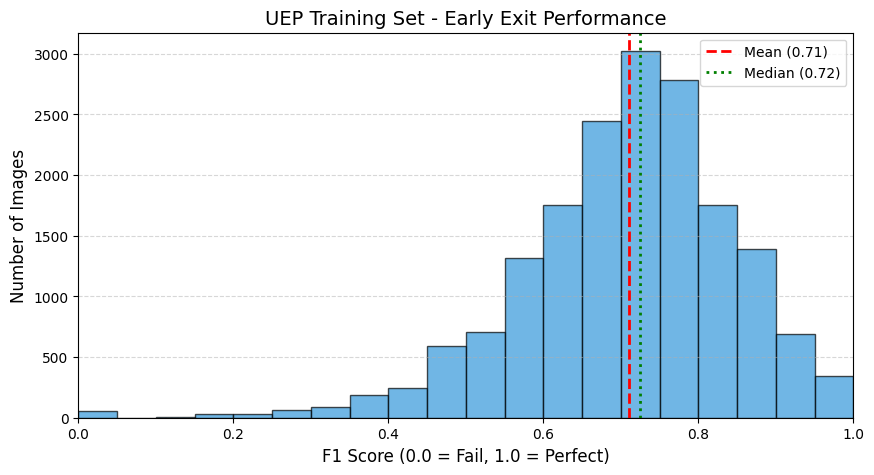

========== Official BDD100K Validation Set - Early Exit Performance Statistics ==========
Total Images:      10000
Average F1 Score:  0.7131
Median F1 Score:   0.7246
Standard Dev:      0.1314
Min: 0.0000 | Max: 1.0000


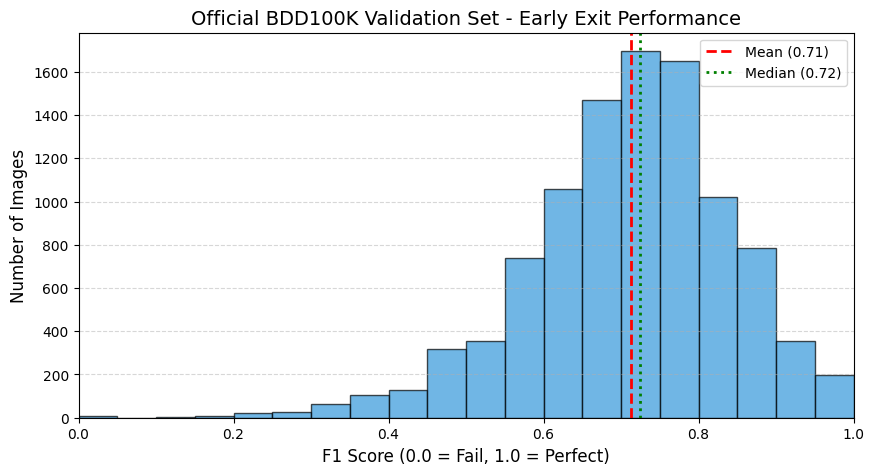

In [14]:
# Plot the distribution of UEP targets
def visualize_f1_distribution(labels, title='F1 Score Distribution'):
    scores = np.array([score for _, score in labels])
    avg_f1 = np.mean(scores)
    median_f1 = np.median(scores)
    std_dev = np.std(scores)
    print(f'========== {title} Statistics ==========')
    print(f'Total Images:      {len(scores)}')
    print(f'Average F1 Score:  {avg_f1:.4f}')
    print(f'Median F1 Score:   {median_f1:.4f}')
    print(f'Standard Dev:      {std_dev:.4f}')
    print(f'Min: {scores.min():.4f} | Max: {scores.max():.4f}')
    print('==========================================')
    plt.figure(figsize=(10, 5))
    plt.hist(scores, bins=20, range=(0.0, 1.0), color='#3498db', edgecolor='black', alpha=0.7)
    plt.axvline(avg_f1, color='red', linestyle='--', linewidth=2, label=f'Mean ({avg_f1:.2f})')
    plt.axvline(median_f1, color='green', linestyle=':', linewidth=2, label=f'Median ({median_f1:.2f})')
    plt.title(title, fontsize=14)
    plt.xlabel('F1 Score (0.0 = Fail, 1.0 = Perfect)', fontsize=12)
    plt.ylabel('Number of Images', fontsize=12)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.xlim(0, 1.0)
    plt.show()

visualize_f1_distribution(train_labels, title='UEP Training Set - Early Exit Performance')
visualize_f1_distribution(val_labels, title='Official BDD100K Validation Set - Early Exit Performance')

## UEP regressors

Trains MobileNetV3-Small, EfficientNet-B0 and ResNet18 regressors (ImageNet-initialised, MSE loss, Adam, up to 50 epochs with early stopping). Each model checkpoints its weights, optimizer, epoch, best model and early-stopping state every epoch, so training can resume.

In [15]:
class ExitDataset(Dataset):
    def __init__(self, img_dir, csv_path, transform=None):
        self.img_dir = img_dir
        self.df = pd.read_csv(csv_path)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.iloc[idx, 0]
        label = float(self.df.iloc[idx, 1])
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32)


# Image transforms for the UEP regressors
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
val_test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = ExitDataset(str(TRAIN_IMAGES_DIR), str(TRAIN_LABELS_CSV), train_transform)
val_dataset = ExitDataset(str(VAL_IMAGES_DIR), str(VAL_LABELS_CSV), val_test_transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=4, persistent_workers=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=4, persistent_workers=True, pin_memory=True)
print(f'UEP loaders: train={len(train_dataset)} from predictor25, validation={len(val_dataset)} from official BDD100K val')

UEP loaders: train=17500 from predictor25, validation=10000 from official BDD100K val


In [16]:
def get_regression_model(model_name):
    if model_name == 'mobilenet_v3_small':
        model = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
        in_features = model.classifier[-1].in_features
        model.classifier[-1] = nn.Linear(in_features, 1)
    elif model_name == 'efficientnet_b0':
        weights = EfficientNet_B0_Weights.DEFAULT
        model = models.efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, 1)
    elif model_name == 'resnet18':
        weights = ResNet18_Weights.DEFAULT
        model = models.resnet18(weights=weights)
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, 1)
    else:
        raise ValueError(f'Unsupported UEP model: {model_name}')
    return model


def torch_load_checkpoint(checkpoint_path, map_location):
    try:
        return torch.load(checkpoint_path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(checkpoint_path, map_location=map_location)


UEP_MODEL_NAMES = ['mobilenet_v3_small', 'efficientnet_b0', 'resnet18']
UEP_PROTOCOL = {
    'version': 3,
    'models': UEP_MODEL_NAMES,
    'train_population': 'all predictor25 images from BDD100K official train',
    'validation_population': 'official BDD100K val',
    'train_image_count': len(uep_train_image_names),
    'validation_image_count': len(uep_val_image_names),
}
UEP_PROTOCOL_PATH = UEP_RUN_DIR / 'protocol.json'
existing_model_checkpoints = list(UEP_RUN_DIR.glob('*/last.pt')) + list(UEP_RUN_DIR.glob('*/best.pt'))
if UEP_PROTOCOL_PATH.is_file():
    if json.loads(UEP_PROTOCOL_PATH.read_text()) != UEP_PROTOCOL:
        raise RuntimeError('Existing UEP checkpoints use a different data protocol/model set. Do not resume them into this experiment.')
elif existing_model_checkpoints:
    raise RuntimeError('Existing UEP checkpoints lack protocol metadata and cannot safely be resumed. Preserve them separately, then start this protocol cleanly.')
else:
    UEP_PROTOCOL_PATH.write_text(json.dumps(UEP_PROTOCOL, indent=2) + '\n')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion = nn.MSELoss()
trained_uep = {}

for model_name in UEP_MODEL_NAMES:
    model_run_dir = UEP_RUN_DIR / model_name
    model_run_dir.mkdir(parents=True, exist_ok=True)
    last_checkpoint = model_run_dir / 'last.pt'
    best_checkpoint = model_run_dir / 'best.pt'
    completed_marker = model_run_dir / 'stage_completed.json'
    deployment_weights = MODELS_DIR / f'uep_{model_name}.pth'

    print(f'\n{"="*40}\nStarting Training: {model_name}\n{"="*40}')
    model = get_regression_model(model_name).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-3)
    start_epoch = 0
    patience_counter = 0
    best_val_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())

    if completed_marker.is_file() and last_checkpoint.is_file():
        print(f'UEP {model_name} stage already complete. Reusing: {last_checkpoint}')
        checkpoint = torch_load_checkpoint(best_checkpoint if best_checkpoint.is_file() else last_checkpoint, device)
        model.load_state_dict(checkpoint['model_state_dict'])
        best_val_loss = float(checkpoint['best_val_loss'])
    elif last_checkpoint.is_file():
        print(f'Found existing checkpoint:\n{last_checkpoint}\n\nResuming UEP {model_name} training...')
        checkpoint = torch_load_checkpoint(last_checkpoint, device)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        start_epoch = int(checkpoint['epoch']) + 1
        patience_counter = int(checkpoint['patience_counter'])
        best_val_loss = float(checkpoint['best_val_loss'])
        best_model_wts = checkpoint['best_model_wts']
    else:
        print(f'No checkpoint found. Starting UEP {model_name} from ImageNet pretrained weights.')

    if not completed_marker.is_file():
        for epoch in range(start_epoch, UEP_EPOCHS):
            model.train()
            running_loss = 0.0
            for images, targets in train_loader:
                images = images.to(device)
                targets = targets.to(device).unsqueeze(1)
                optimizer.zero_grad()
                outputs = torch.sigmoid(model(images))
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()
                running_loss += loss.item()

            model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for images, targets in val_loader:
                    images = images.to(device)
                    targets = targets.to(device).unsqueeze(1)
                    val_loss += criterion(torch.sigmoid(model(images)), targets).item()

            train_mse = running_loss / len(train_loader)
            val_mse = val_loss / len(val_loader)
            print(f'Epoch {epoch+1:02d} | Train MSE: {train_mse:.4f} | Val MSE: {val_mse:.4f}', end=' ')
            if val_mse < best_val_loss:
                print(f'-> Saved Best (Prev: {best_val_loss:.4f})')
                best_val_loss = val_mse
                patience_counter = 0
                best_model_wts = copy.deepcopy(model.state_dict())
                torch.save({
                    'epoch': epoch, 'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(), 'best_model_wts': best_model_wts,
                    'best_val_loss': best_val_loss, 'patience_counter': patience_counter,
                    'model_name': model_name,
                }, best_checkpoint)
            else:
                patience_counter += 1
                print(f'-> No improvement ({patience_counter}/{UEP_PATIENCE})')

            # Per-epoch resumable state, including optimizer and early-stopping state.
            torch.save({
                'epoch': epoch, 'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(), 'best_model_wts': best_model_wts,
                'best_val_loss': best_val_loss, 'patience_counter': patience_counter,
                'model_name': model_name,
            }, last_checkpoint)
            if patience_counter >= UEP_PATIENCE:
                print(f'Early stopping triggered for {model_name}!')
                break

        model.load_state_dict(best_model_wts)
        write_stage_complete(completed_marker, stage=f'uep_{model_name}', best_val_loss=best_val_loss)

    if not last_checkpoint.is_file():
        raise FileNotFoundError(f'UEP training did not create {last_checkpoint}')
    if best_checkpoint.is_file():
        model.load_state_dict(torch_load_checkpoint(best_checkpoint, device)['model_state_dict'])
    torch.save(model.state_dict(), deployment_weights)
    trained_uep[model_name] = {
        'last': last_checkpoint,
        'best': best_checkpoint,
        'deployment': deployment_weights,
        'best_val_loss': best_val_loss,
    }
    print(f'Finished {model_name}. Best MSE: {best_val_loss:.4f}. Saved to {deployment_weights}')

print('\nAll UEP models trained or restored.')


Starting Training: mobilenet_v3_small
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 155MB/s]

No checkpoint found. Starting UEP mobilenet_v3_small from ImageNet pretrained weights.


Epoch 01 | Train MSE: 0.0203 | Val MSE: 0.0288 -> Saved Best (Prev: inf)
Epoch 02 | Train MSE: 0.0183 | Val MSE: 0.0275 -> Saved Best (Prev: 0.0288)
Epoch 03 | Train MSE: 0.0177 | Val MSE: 0.0274 -> Saved Best (Prev: 0.0275)
Epoch 04 | Train MSE: 0.0175 | Val MSE: 0.0227 -> Saved Best (Prev: 0.0274)
Epoch 05 | Train MSE: 0.0173 | Val MSE: 0.0288 -> No improvement (1/5)
Epoch 06 | Train MSE: 0.0172 | Val MSE: 0.0266 -> No improvement (2/5)
Epoch 07 | Train MSE: 0.0172 | Val MSE: 0.0293 -> No improvement (3/5)
Epoch 08 | Train MSE: 0.0170 | Val MSE: 0.0338 -> No improvement (4/5)
Epoch 09 | Train MSE: 0.0171 | Val MSE: 0.0285 -> No improvement (5/5)
Early stopping triggered for mobilenet_v3_small!
Finished mobilenet_v3_small. Best MSE: 0.0227. Saved to /kaggle/working/bdd100k_75_25_experiment/models/uep_mobilenet_v3_small.pth

Starting Training: efficientnet_b0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/

100%|██████████| 20.5M/20.5M [00:00<00:00, 214MB/s]


No checkpoint found. Starting UEP efficientnet_b0 from ImageNet pretrained weights.
Epoch 01 | Train MSE: 0.0209 | Val MSE: 0.0171 -> Saved Best (Prev: inf)
Epoch 02 | Train MSE: 0.0179 | Val MSE: 0.0170 -> Saved Best (Prev: 0.0171)
Epoch 03 | Train MSE: 0.0167 | Val MSE: 0.0165 -> Saved Best (Prev: 0.0170)
Epoch 04 | Train MSE: 0.0162 | Val MSE: 0.0173 -> No improvement (1/5)
Epoch 05 | Train MSE: 0.0156 | Val MSE: 0.0170 -> No improvement (2/5)
Epoch 06 | Train MSE: 0.0157 | Val MSE: 0.0167 -> No improvement (3/5)
Epoch 07 | Train MSE: 0.0154 | Val MSE: 0.0170 -> No improvement (4/5)
Epoch 08 | Train MSE: 0.0152 | Val MSE: 0.0172 -> No improvement (5/5)
Early stopping triggered for efficientnet_b0!
Finished efficientnet_b0. Best MSE: 0.0165. Saved to /kaggle/working/bdd100k_75_25_experiment/models/uep_efficientnet_b0.pth

Starting Training: resnet18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 212MB/s]


No checkpoint found. Starting UEP resnet18 from ImageNet pretrained weights.
Epoch 01 | Train MSE: 0.0200 | Val MSE: 0.0247 -> Saved Best (Prev: inf)
Epoch 02 | Train MSE: 0.0175 | Val MSE: 0.0169 -> Saved Best (Prev: 0.0247)
Epoch 03 | Train MSE: 0.0165 | Val MSE: 0.0158 -> Saved Best (Prev: 0.0169)
Epoch 04 | Train MSE: 0.0164 | Val MSE: 0.0159 -> No improvement (1/5)
Epoch 05 | Train MSE: 0.0166 | Val MSE: 0.0169 -> No improvement (2/5)
Epoch 06 | Train MSE: 0.0166 | Val MSE: 0.0173 -> No improvement (3/5)
Epoch 07 | Train MSE: 0.0167 | Val MSE: 0.0163 -> No improvement (4/5)
Epoch 08 | Train MSE: 0.0168 | Val MSE: 0.0162 -> No improvement (5/5)
Early stopping triggered for resnet18!
Finished resnet18. Best MSE: 0.0158. Saved to /kaggle/working/bdd100k_75_25_experiment/models/uep_resnet18.pth

All UEP models trained or restored.


## UEP evaluation on the official BDD100K validation set

Computes per-image early- and final-exit F1-scores, sweeps the routing threshold (Pareto frontier and threshold sensitivity), reports parameter savings at each retention level, and reports mAP at the selected threshold. These images are never used for training.

In [17]:
# Per-image F1-score used for system evaluation
def compute_f1_iou(gt_boxes, pred_boxes, iou_thresh=0.5):
    if len(gt_boxes) == 0 and len(pred_boxes) == 0: return 1.0
    if len(gt_boxes) == 0: return 0.0
    if len(pred_boxes) == 0: return 0.0
    matched_gt = set()
    tp = 0
    for pred in pred_boxes:
        best_iou = 0
        best_gt_idx = -1
        for idx, gt in enumerate(gt_boxes):
            if idx in matched_gt: continue
            xA = max(pred[0], gt[0]); yA = max(pred[1], gt[1])
            xB = min(pred[2], gt[2]); yB = min(pred[3], gt[3])
            interArea = max(0, xB - xA) * max(0, yB - yA)
            boxAArea = (pred[2] - pred[0]) * (pred[3] - pred[1])
            boxBArea = (gt[2] - gt[0]) * (gt[3] - gt[1])
            iou = interArea / float(boxAArea + boxBArea - interArea + 1e-6)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = idx
        if best_iou >= iou_thresh:
            tp += 1
            matched_gt.add(best_gt_idx)
    fn = len(gt_boxes) - tp
    fp = len(pred_boxes) - tp
    prec = tp / (tp + fp + 1e-6)
    rec = tp / (tp + fn + 1e-6)
    return 2 * (prec * rec) / (prec + rec + 1e-6)


print('Loading YOLO models trained only on detector75...')
model_early = YOLO(str(EARLY_EXIT_WEIGHTS)).to('cuda:0')
model_final = YOLO(str(DETECTOR_WEIGHTS)).to('cuda:1')
ground_truth_performance = []

print('Pre-computing YOLO performance on official BDD100K validation images...')
# CSV and this manifest share the persisted image order, so predictor scores and target metrics align.
for img_name in tqdm(uep_val_image_names):
    img_path = VAL_IMAGES_DIR / img_name
    txt_path = VAL_LABELS_DIR / Path(img_name).with_suffix('.txt')
    gt_boxes = []
    if txt_path.exists():
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        with open(txt_path, 'r') as f:
            for line in f:
                parts = list(map(float, line.strip().split()))
                x1 = int((parts[1] - parts[3]/2) * w)
                y1 = int((parts[2] - parts[4]/2) * h)
                x2 = int((parts[1] + parts[3]/2) * w)
                y2 = int((parts[2] + parts[4]/2) * h)
                gt_boxes.append([x1, y1, x2, y2])

    res_e = model_early.predict(str(img_path), verbose=False, imgsz=640, conf=0.25, device='cuda:0')[0]
    boxes_e = res_e.boxes.xyxy.cpu().numpy().tolist()
    score_early = compute_f1_iou(gt_boxes, boxes_e)
    res_f = model_final.predict(str(img_path), verbose=False, imgsz=640, conf=0.25, device='cuda:1')[0]
    boxes_f = res_f.boxes.xyxy.cpu().numpy().tolist()
    score_final = compute_f1_iou(gt_boxes, boxes_f)
    ground_truth_performance.append({'img': img_name, 'early': score_early, 'final': score_final})

if len(ground_truth_performance) != len(val_dataset):
    raise RuntimeError('UEP evaluation metric rows and validation loader rows are misaligned.')
print(f'Pre-computation complete for {len(ground_truth_performance)} official BDD100K validation images.')

Loading YOLO models trained only on detector75...
Pre-computing YOLO performance on official BDD100K validation images...


  0%|          | 0/10000 [00:00<?, ?it/s]

Pre-computation complete for 10000 official BDD100K validation images.


In [18]:
def load_predictor(model_name, checkpoint_path):
    predictor_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    predictor = get_regression_model(model_name)
    checkpoint = torch_load_checkpoint(checkpoint_path, predictor_device)
    predictor.load_state_dict(checkpoint['model_state_dict'])
    predictor.to(predictor_device)
    predictor.eval()
    return predictor


predictors = {
    'MobileNetV3': load_predictor('mobilenet_v3_small', trained_uep['mobilenet_v3_small']['best'] if trained_uep['mobilenet_v3_small']['best'].is_file() else trained_uep['mobilenet_v3_small']['last']),
    'EfficientNet': load_predictor('efficientnet_b0', trained_uep['efficientnet_b0']['best'] if trained_uep['efficientnet_b0']['best'].is_file() else trained_uep['efficientnet_b0']['last']),
    'ResNet18': load_predictor('resnet18', trained_uep['resnet18']['best'] if trained_uep['resnet18']['best'].is_file() else trained_uep['resnet18']['last']),
}


def evaluate_predictor(predictor, val_loader, gt_perf):
    device = next(predictor.parameters()).device
    pred_scores = []
    print('Running Upfront Predictor...')
    with torch.no_grad():
        for images, _ in tqdm(val_loader):
            images = images.to(device)
            outputs = predictor(images)
            probs = torch.sigmoid(outputs).cpu().numpy().flatten()
            pred_scores.extend(probs)
    pred_scores = np.array(pred_scores)
    actual_early = np.array([x['early'] for x in gt_perf])
    actual_final = np.array([x['final'] for x in gt_perf])
    thresholds = np.linspace(0.0, 1.0, 100)
    curve = []
    for thresh in thresholds:
        early_mask = pred_scores >= thresh
        final_mask = ~early_mask
        system_score = (np.sum(actual_early[early_mask]) + np.sum(actual_final[final_mask])) / len(pred_scores)
        efficiency = np.mean(early_mask)
        curve.append((efficiency, system_score))
    return curve


curves = {}
for name, predictor in predictors.items():
    print(f'\nEvaluating {name}...')
    curves[name] = evaluate_predictor(predictor, val_loader, ground_truth_performance)

with open(RESULTS_DIR / 'uep_curves.json', 'w') as file:
    json.dump({name: [[float(x), float(y)] for x, y in curve] for name, curve in curves.items()}, file, indent=2)
print(f'Saved threshold curves: {RESULTS_DIR / "uep_curves.json"}')


Evaluating MobileNetV3...
Running Upfront Predictor...


  0%|          | 0/157 [00:00<?, ?it/s]


Evaluating EfficientNet...
Running Upfront Predictor...


  0%|          | 0/157 [00:00<?, ?it/s]


Evaluating ResNet18...
Running Upfront Predictor...


  0%|          | 0/157 [00:00<?, ?it/s]

Saved threshold curves: /kaggle/working/bdd100k_75_25_experiment/results/uep_curves.json


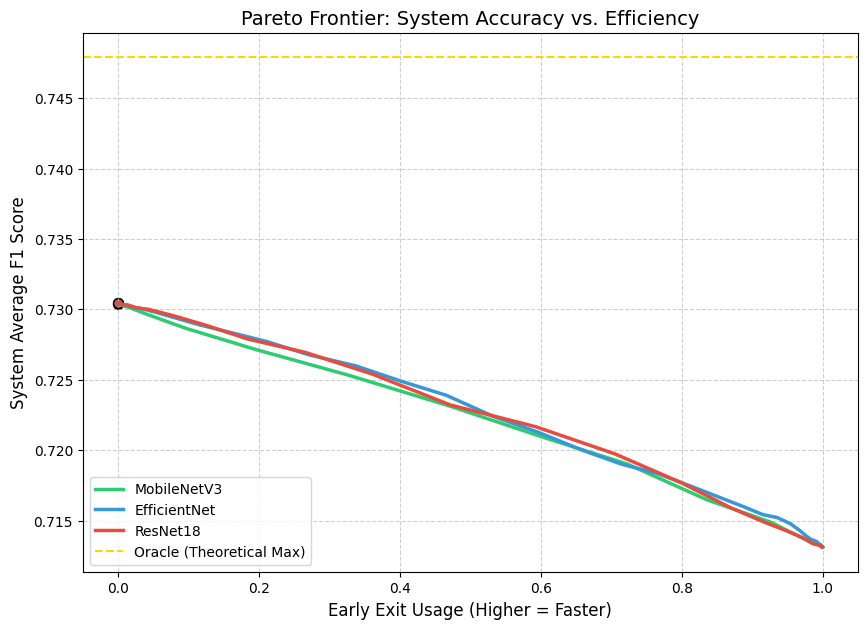

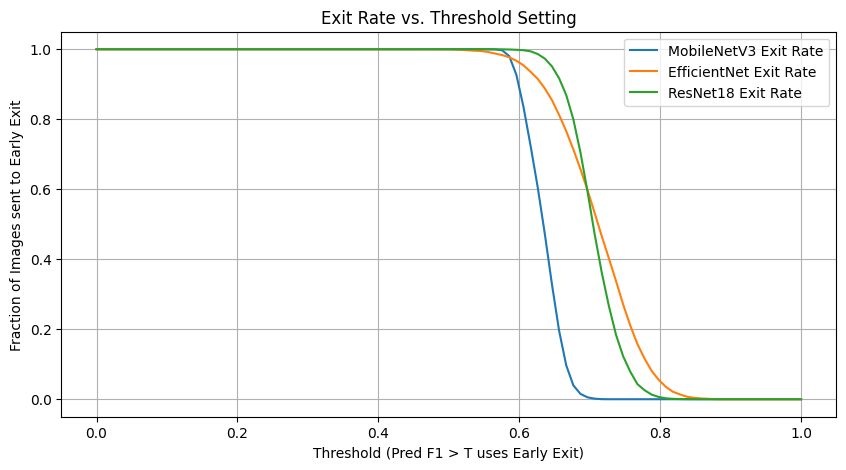

BASELINE METRICS
Oracle F1 (Theoretical Max): 0.7479
Final Model Only F1:         0.7304
Early Model Only F1:         0.7131

                   AUC Max Eff @ 99% Acc Max Eff @ 95% Acc   Peak F1
Model                                                               
MobileNetV3   0.719528             47.1%            100.0%  0.730416
EfficientNet  0.718410             46.6%            100.0%  0.730431
ResNet18      0.718360             47.1%            100.0%  0.730416
Saved detailed stats: /kaggle/working/bdd100k_75_25_experiment/results/uep_detailed_stats.csv


In [19]:
# Pareto frontier and threshold-sensitivity plots
plt.figure(figsize=(10, 7))
colors = {'MobileNetV3': '#2ecc71', 'EfficientNet': '#3498db', 'ResNet18': '#e74c3c'}
for name, curve in curves.items():
    eff, acc = zip(*curve)
    plt.plot(eff, acc, label=name, color=colors[name], linewidth=2.5)
    max_idx = np.argmax(acc)
    plt.scatter(eff[max_idx], acc[max_idx], s=50, color=colors[name], edgecolors='black')
plt.title('Pareto Frontier: System Accuracy vs. Efficiency', fontsize=14)
plt.xlabel('Early Exit Usage (Higher = Faster)', fontsize=12)
plt.ylabel('System Average F1 Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
actual_early = np.array([x['early'] for x in ground_truth_performance])
actual_final = np.array([x['final'] for x in ground_truth_performance])
oracle_perf = np.maximum(actual_early, actual_final).mean()
plt.axhline(oracle_perf, color='gold', linestyle='--', label='Oracle (Theoretical Max)')
plt.legend()
plt.savefig(RESULTS_DIR / 'pareto_frontier.png', bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 5))
thresholds = np.linspace(0.0, 1.0, 100)
for name, curve in curves.items():
    eff, acc = zip(*curve)
    plt.plot(thresholds, eff, label=f'{name} Exit Rate', linestyle='-')
plt.title('Exit Rate vs. Threshold Setting')
plt.xlabel('Threshold (Pred F1 > T uses Early Exit)')
plt.ylabel('Fraction of Images sent to Early Exit')
plt.grid(True)
plt.legend()
plt.savefig(RESULTS_DIR / 'exit_rate_threshold.png', bbox_inches='tight')
plt.show()


def print_detailed_stats(curves, gt_perf):
    actual_early = np.array([x['early'] for x in gt_perf])
    actual_final = np.array([x['final'] for x in gt_perf])
    oracle_f1 = np.maximum(actual_early, actual_final).mean()
    all_final_f1 = actual_final.mean()
    all_early_f1 = actual_early.mean()
    print('='*60)
    print('BASELINE METRICS')
    print('='*60)
    print(f'Oracle F1 (Theoretical Max): {oracle_f1:.4f}')
    print(f'Final Model Only F1:         {all_final_f1:.4f}')
    print(f'Early Model Only F1:         {all_early_f1:.4f}')
    print('='*60 + '\n')
    stats = []
    for name, curve in curves.items():
        effs, accs = map(np.array, zip(*curve))
        valid_99 = np.where(accs >= all_final_f1 * 0.99)[0]
        valid_95 = np.where(accs >= all_final_f1 * 0.95)[0]
        stats.append({
            'Model': name,
            'AUC': np.mean(accs),
            'Max Eff @ 99% Acc': f'{(effs[valid_99].max() if len(valid_99) else 0)*100:.1f}%',
            'Max Eff @ 95% Acc': f'{(effs[valid_95].max() if len(valid_95) else 0)*100:.1f}%',
            'Peak F1': accs.max(),
        })
    df = pd.DataFrame(stats).set_index('Model').sort_values('AUC', ascending=False)
    print(df)
    return df


stats_df = print_detailed_stats(curves, ground_truth_performance)
stats_df.to_csv(RESULTS_DIR / 'uep_detailed_stats.csv')
print(f'Saved detailed stats: {RESULTS_DIR / "uep_detailed_stats.csv"}')

In [20]:
# Parameter savings at each retention level (final-exit-only baseline from the validation set)
def analyze_savings_potential(curves, model_name='MobileNetV3', router_cost=2.5, early_cost=11.0, final_cost=26.0):
    curve = curves[model_name]
    effs, accs = map(np.array, zip(*curve))
    baseline_acc = np.array([x['final'] for x in ground_truth_performance]).mean()
    baseline_cost = final_cost
    print(f'Analysis for {model_name} (Router Cost: {router_cost}M)')
    print(f'{"Target Acc %":<15} | {"Min F1":<10} | {"Exit Rate":<10} | {"Sys Cost (M)":<15} | {"SAVINGS":<10}')
    print('-' * 75)
    for retention in [1.0, 0.995, 0.99, 0.98, 0.97, 0.96, 0.95]:
        target_f1 = baseline_acc * retention
        valid_indices = np.where(accs >= target_f1)[0]
        best_eff = effs[valid_indices].max() if len(valid_indices) else 0.0
        sys_cost = router_cost + best_eff * early_cost + (1.0 - best_eff) * final_cost
        savings = (baseline_cost - sys_cost) / baseline_cost * 100
        print(f'{retention*100:>5.1f}%          | {target_f1:.4f}     | {best_eff*100:>5.1f}%     | {sys_cost:>5.2f}           | {savings:>5.1f}%')


analyze_savings_potential(curves, model_name='MobileNetV3', router_cost=2.5)

Analysis for MobileNetV3 (Router Cost: 2.5M)
Target Acc %    | Min F1     | Exit Rate  | Sys Cost (M)    | SAVINGS   
---------------------------------------------------------------------------
100.0%          | 0.7304     |   0.0%     | 28.50           |  -9.6%
 99.5%          | 0.7268     |  19.6%     | 25.56           |   1.7%
 99.0%          | 0.7231     |  47.1%     | 21.43           |  17.6%
 98.0%          | 0.7158     |  83.5%     | 15.97           |  38.6%
 97.0%          | 0.7085     | 100.0%     | 13.50           |  48.1%
 96.0%          | 0.7012     | 100.0%     | 13.50           |  48.1%
 95.0%          | 0.6939     | 100.0%     | 13.50           |  48.1%


In [21]:
# Threshold search and weighted mAP on the official BDD100K validation set
target_retention = 0.98

def find_threshold_for_target(predictor, val_loader, gt_perf, target_retention=0.97):
    device = next(predictor.parameters()).device
    pred_scores = []
    print('Scanning thresholds...')
    with torch.no_grad():
        for images, _ in tqdm(val_loader, desc='Predicting F1'):
            images = images.to(device)
            outputs = predictor(images)
            probs = torch.sigmoid(outputs).cpu().numpy().flatten()
            pred_scores.extend(probs)
    pred_scores = np.array(pred_scores)
    actual_early = np.array([x['early'] for x in gt_perf])
    actual_final = np.array([x['final'] for x in gt_perf])
    target_acc = actual_final.mean() * target_retention
    best_thresh, best_exit_rate, best_sys_acc = 0.0, 0.0, 0.0
    for thresh in np.linspace(0.0, 1.0, 1000):
        early_mask = pred_scores >= thresh
        final_mask = ~early_mask
        sys_acc = (np.sum(actual_early[early_mask]) + np.sum(actual_final[final_mask])) / len(pred_scores)
        if sys_acc >= target_acc and np.mean(early_mask) > best_exit_rate:
            best_exit_rate = np.mean(early_mask)
            best_thresh = thresh
            best_sys_acc = sys_acc
    return best_thresh, best_exit_rate, best_sys_acc


print('\nRunning YOLO validation for mAP on official BDD100K validation images...')
metrics_early = YOLO(str(EARLY_EXIT_WEIGHTS)).val(data=str(UEP_EVAL_YAML), split='val', verbose=False)
map_early = metrics_early.box.map
metrics_final = YOLO(str(DETECTOR_WEIGHTS)).val(data=str(UEP_EVAL_YAML), split='val', verbose=False)
map_final = metrics_final.box.map

final_results = {}
for predictor_name, predictor in predictors.items():
    optimal_thresh, exit_rate, sys_acc = find_threshold_for_target(predictor, val_loader, ground_truth_performance, target_retention)
    system_map = exit_rate * map_early + (1 - exit_rate) * map_final
    final_results[predictor_name] = {
        'evaluation_population': 'official BDD100K validation set',
        'evaluation_image_count': len(val_images),
        'target_retention': target_retention,
        'threshold': float(optimal_thresh),
        'early_exit_rate': float(exit_rate),
        'system_f1': float(sys_acc),
        'early_map50_95': float(map_early),
        'final_map50_95': float(map_final),
        'weighted_system_map50_95': float(system_map),
    }
    print('\n' + '='*40)
    print(f'FINAL SYSTEM RESULTS — {predictor_name}')
    print('='*40)
    print(f'Threshold:             {optimal_thresh:.4f}')
    print(f'Early-exit rate:       {exit_rate*100:.1f}%')
    print(f'System F1:             {sys_acc:.4f}')
    print(f'Early Model mAP50-95:  {map_early:.4f}')
    print(f'Final Model mAP50-95:  {map_final:.4f}')
    print(f'Weighted mAP50-95:     {system_map:.4f}')

(RESULTS_DIR / 'final_results.json').write_text(json.dumps(final_results, indent=2) + '\n')
print(f'\nSaved final results: {RESULTS_DIR / "final_results.json"}')


Running YOLO validation for mAP on official BDD100K validation images...
Ultralytics 8.4.172 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:1 (Tesla T4, 14912MiB)
YOLOv8m_early summary (fused): 53 layers, 10,172,036 parameters, 0 gradients
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 76.4±70.5 MB/s, size: 52.8 KB)
val: Scanning /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val/labels... 10000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10000/10000 1.1Kit/s 8.8s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 625/625 4.6it/s 2:15
                   all      10000     185526      0.737      0.489       0.54      0.296
Speed: 0.5ms preprocess, 9.2ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved 

Predicting F1:   0%|          | 0/157 [00:00<?, ?it/s]


FINAL SYSTEM RESULTS — MobileNetV3
Threshold:             0.6036
Early-exit rate:       86.2%
System F1:             0.7159
Early Model mAP50-95:  0.2964
Final Model mAP50-95:  0.3201
Weighted mAP50-95:     0.2996
Scanning thresholds...


Predicting F1:   0%|          | 0/157 [00:00<?, ?it/s]


FINAL SYSTEM RESULTS — EfficientNet
Threshold:             0.6336
Early-exit rate:       89.4%
System F1:             0.7159
Early Model mAP50-95:  0.2964
Final Model mAP50-95:  0.3201
Weighted mAP50-95:     0.2989
Scanning thresholds...


Predicting F1:   0%|          | 0/157 [00:00<?, ?it/s]


FINAL SYSTEM RESULTS — ResNet18
Threshold:             0.6657
Early-exit rate:       87.5%
System F1:             0.7158
Early Model mAP50-95:  0.2964
Final Model mAP50-95:  0.3201
Weighted mAP50-95:     0.2993

Saved final results: /kaggle/working/bdd100k_75_25_experiment/results/final_results.json


## Save the experiment artifacts

`/kaggle/working` does not persist across sessions. Save `bdd100k_75_25_experiment` as notebook output or a Kaggle Dataset, and restore it under `/kaggle/working/` to resume from `last.pt` with the same split.

In [22]:
uep_artifacts = [UEP_PROTOCOL_PATH]
for model_name, artifact in trained_uep.items():
    uep_artifacts.extend([artifact['last'], artifact['best'], artifact['deployment']])

important_artifacts = {
    'Split': [DETECTOR_SPLIT, PREDICTOR_SPLIT, SPLIT_METADATA],
    'Detector': [DETECTOR_LAST, DETECTOR_BEST],
    'Early exit': [EARLY_EXIT_LAST, EARLY_EXIT_BEST],
    'UEP (MobileNetV3-Small, EfficientNet-B0, ResNet18)': uep_artifacts,
    'Configs': [DETECTOR_YAML, UEP_EVAL_YAML, EARLY_MODEL_YAML],
    'Results': [RESULTS_DIR / 'uep_curves.json', RESULTS_DIR / 'uep_detailed_stats.csv', RESULTS_DIR / 'final_results.json'],
}
print(f'Experiment root: {EXPERIMENT_DIR}')
for group, paths in important_artifacts.items():
    print(f'\n{group}:')
    for artifact_path in paths:
        print(f'  {artifact_path}  [{"present" if Path(artifact_path).exists() else "not created yet"}]')

print('\nData populations:')
print(f'  Detector training data: 75% BDD100K train = {len(detector_relative)} images')
print(f'  UEP training data:       25% BDD100K train = {len(predictor_relative)} images')
print(f'  Shared validation data:  BDD100K val = {len(val_images)} images (untouched)')

Experiment root: /kaggle/working/bdd100k_75_25_experiment

Split:
  /kaggle/working/bdd100k_75_25_experiment/splits/detector75.txt  [present]
  /kaggle/working/bdd100k_75_25_experiment/splits/predictor25.txt  [present]
  /kaggle/working/bdd100k_75_25_experiment/splits/split_metadata.json  [present]

Detector:
  /kaggle/working/bdd100k_75_25_experiment/checkpoints/yolov8m_detector/weights/last.pt  [present]
  /kaggle/working/bdd100k_75_25_experiment/checkpoints/yolov8m_detector/weights/best.pt  [present]

Early exit:
  /kaggle/working/bdd100k_75_25_experiment/checkpoints/yolov8m_early_exit/weights/last.pt  [present]
  /kaggle/working/bdd100k_75_25_experiment/checkpoints/yolov8m_early_exit/weights/best.pt  [present]

UEP (MobileNetV3-Small, EfficientNet-B0, ResNet18):
  /kaggle/working/bdd100k_75_25_experiment/checkpoints/uep/protocol.json  [present]
  /kaggle/working/bdd100k_75_25_experiment/checkpoints/uep/mobilenet_v3_small/last.pt  [present]
  /kaggle/working/bdd100k_75_25_experiment